In [1]:
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
cypher_path = '../cyphers/'
client_cypher_paths = [cypher_path + 'cs' + str(i+1) + '.json' for i in range(5)]
server_cypher_paths = [cypher_path + 'sc' + str(i+1) + '.json' for i in range(5)]
print(client_cypher_paths)
print(server_cypher_paths)

['../cyphers/cs1.json', '../cyphers/cs2.json', '../cyphers/cs3.json', '../cyphers/cs4.json', '../cyphers/cs5.json']
['../cyphers/sc1.json', '../cyphers/sc2.json', '../cyphers/sc3.json', '../cyphers/sc4.json', '../cyphers/sc5.json']


In [3]:
server_cyphers = [pd.read_json(scp, typ='series') for scp in server_cypher_paths]
client_cyphers = [pd.read_json(ccp, typ='series') for ccp in client_cypher_paths]

In [41]:
def decrypt_affine(cypher, a_inv, b):
    plain = ''
    for c in cypher:
        if c == ' ': 
            plain += ' '
            continue
        c = ord(c) - ord('A')
        plain += chr((a_inv * (c - b) % 26) + 65)
    return plain
def decrypt_affine_pairs(cypher, a_inv, b):
    plain = ''
    if len(cypher) % 2: 
        print('odd cipher. can not decrypt')
        return 
    for i in range(0, len(cypher), 2):
        base = ord('A')
        un, ln = ord(cypher[i])-base, ord(cypher[i+1])-base
        un = (a_inv * (un - b) % 26)
        ln = (a_inv * (ln - b) % 26)
        plain += chr(un * 16 + ln)
    return plain
        

## Server Messages

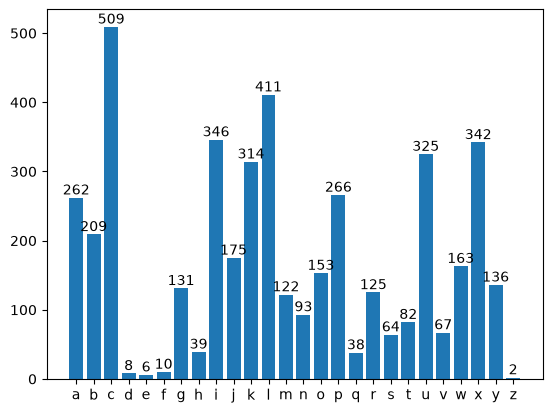

In [5]:
combined_server_cypher = ''
for server_cypher in server_cyphers:
    combined_server_cypher += server_cypher.ciphertext

counts = Counter(c for c in combined_server_cypher.lower() if c.isalpha())

letters, freq = zip(*sorted(counts.items()))

bars = plt.bar(letters, freq)
plt.bar_label(bars)
plt.show()

From frequency analysis:<br>
E: C <br>
T: L <br>
<br>
Equations to solve to find the values for a and b are: <br>
'C' = a * 'E' + b mod 26<br>
'L' = a * 'T' + b mod 26<br>
<br>
Solving the system of linear equations give: <br>
a = 11 (a_inv = 19) <br>
b = 10

In [6]:
for c in ['E', 'C', 'T', 'L']:
    print(f'{c}: {ord(c) - ord('A')}')

E: 4
C: 2
T: 19
L: 11


In [7]:
decrypt_affine(server_cyphers[0].ciphertext, 19, 10)

'IT IS COMPLETELY NORMAL TO FEEL ANXIOUS BEFORE A MAJOR EXAM AS THAT FEELING OFTEN JUST SIGNALS THAT YOU CARE DEEPLY ABOUT DOING WELL TO MANAGE THIS START BY SHIFTING YOUR FOCUS FROM WORRYING ABOUT THE OUTCOME TO FOCUSING ENTIRELY ON THE PREPARATION YOU HAVE ALREADY DONE TRY BREAKING YOUR STUDY TIME INTO SMALLER MANAGEABLE CHUNKS RATHER THAN TRYING TO CRAM EVERYTHING AT ONCE WHICH REDUCES THE FEELING OF BEING OVERWHELMED WHEN ANXIETY SPIKES PRACTICE SIMPLE GROUNDING TECHNIQUES LIKE TAKING SLOW DEEP BREATHSINHALE FOR A COUNT OF FOUR HOLD FOR FOUR AND EXHALE FOR SIXTO CALM YOUR NERVOUS SYSTEM QUICKLY REMEMBER THAT YOUR WORTH IS NOT TIED TO THIS SINGLE TEST SO TRY TO SPEAK TO YOURSELF WITH KINDNESS AND ACKNOWLEDGE THAT YOU HAVE PUT IN THE WORK ALI REMEMBER THAT PREPARATION IS THE ANTIDOTE TO PANIC AND TRUSTING IN YOUR ABILITY TO HANDLE THE MATERIAL IS JUST AS IMPORTANT AS THE MATERIAL ITSELF FOCUS ON SHOWING UP AND DOING YOUR BEST AND ALLOW YOURSELF TO FEEL THE NERVES WITHOUT LETTING THEM

In [47]:
for cipher in server_cyphers:
    cipher = cipher.ciphertext
    print(decrypt_affine(cipher, 19, 10))

IT IS COMPLETELY NORMAL TO FEEL ANXIOUS BEFORE A MAJOR EXAM AS THAT FEELING OFTEN JUST SIGNALS THAT YOU CARE DEEPLY ABOUT DOING WELL TO MANAGE THIS START BY SHIFTING YOUR FOCUS FROM WORRYING ABOUT THE OUTCOME TO FOCUSING ENTIRELY ON THE PREPARATION YOU HAVE ALREADY DONE TRY BREAKING YOUR STUDY TIME INTO SMALLER MANAGEABLE CHUNKS RATHER THAN TRYING TO CRAM EVERYTHING AT ONCE WHICH REDUCES THE FEELING OF BEING OVERWHELMED WHEN ANXIETY SPIKES PRACTICE SIMPLE GROUNDING TECHNIQUES LIKE TAKING SLOW DEEP BREATHSINHALE FOR A COUNT OF FOUR HOLD FOR FOUR AND EXHALE FOR SIXTO CALM YOUR NERVOUS SYSTEM QUICKLY REMEMBER THAT YOUR WORTH IS NOT TIED TO THIS SINGLE TEST SO TRY TO SPEAK TO YOURSELF WITH KINDNESS AND ACKNOWLEDGE THAT YOU HAVE PUT IN THE WORK ALI REMEMBER THAT PREPARATION IS THE ANTIDOTE TO PANIC AND TRUSTING IN YOUR ABILITY TO HANDLE THE MATERIAL IS JUST AS IMPORTANT AS THE MATERIAL ITSELF FOCUS ON SHOWING UP AND DOING YOUR BEST AND ALLOW YOURSELF TO FEEL THE NERVES WITHOUT LETTING THEM 

## Client Messages

Counter({'GK': 43, 'YN': 24, 'JC': 21, 'YV': 20, 'YT': 19, 'YI': 15, 'YF': 14, 'YU': 13, 'JG': 9, 'YM': 9, 'JJ': 8, 'YC': 8, 'YX': 6, 'JR': 6, 'JF': 5, 'JK': 5, 'RT': 5, 'YJ': 4, 'YR': 3, 'YY': 3, 'JU': 2, 'JN': 2, 'JY': 2, 'YB': 2, 'YG': 1})


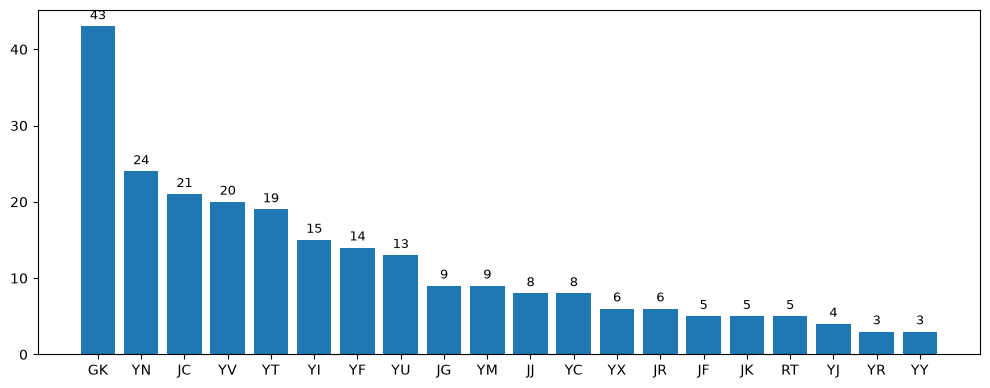

In [ ]:
combined_client_cypher = ''
for client_cypher in client_cyphers:
    combined_client_cypher += client_cypher.message_enc.replace(' ', '')

pair_counts = Counter(
    ''.join(combined_client_cypher[i:i+2]) for i in range(0, len(combined_client_cypher) - 1, 2)
)

pairs, freq = zip(*pair_counts.most_common(20))

fig, ax = plt.subplots(figsize=(10, 4))

bars = ax.bar(pairs, freq)
ax.bar_label(bars, fontsize=9, padding=3)

plt.tight_layout()
plt.show()

In [38]:
even = [ord(combined_client_cypher[i]) - ord('A') for i in range(0, len(combined_client_cypher), 2)]
odd = [ord(combined_client_cypher[i]) - ord('A') for i in range(1, len(combined_client_cypher), 2)]

print (set(even))
print (set(odd))

{24, 9, 6, 17}
{1, 2, 5, 6, 8, 9, 10, 12, 13, 17, 19, 20, 21, 23, 24}


From frequency analysis (more details in report): <br>

GK = space (most frequent)<br>
YN = E

In [42]:
decrypt_affine_pairs(client_cyphers[0].message_enc.replace(' ', ''), 19, 10)

'how can i manage anxiety before an important exam?'

In [44]:
for cipher in client_cyphers:
    cipher = cipher.message_enc.replace(' ', '')
    print(decrypt_affine_pairs(cipher, 19, 10))

how can i manage anxiety before an important exam?
why do i feel tired and unmotivated all the time?
what can i do to stop overthinking at night?
how do i cope with feeling lonely around other people?
what are some healthy ways to handle stress at work?
